<a href="https://colab.research.google.com/github/estefania-apaza/Evaluacion-2-Taller-Informaci-n/blob/main/Evaluaci%C3%B3n_2_reproducible.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [122]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [123]:
# Extraemos el archivo
archivo = "https://github.com/estefania-apaza/Evaluacion-2-Taller-Informaci-n/raw/main/Comparacio%CC%81n1y2vuelta_EleccionesPresidenciales.xlsx"

df = pd.read_excel(archivo, sheet_name="BD")

print(df.shape)
df.head()

(196, 10)


,Departamento,Provincia,pv2021_KF,pv2021_PC,sv2021_KF,sv2021_PC,pv2026_KF,pv2026_RS,sv2026_KF,sv2026_RS
0,AMAZONAS,BAGUA,12.71,27.476527,29.31,70.69,14.972,43.562,29.898,70.102
1,AMAZONAS,BONGARA,18.09,33.772704,38.35,61.65,23.949,27.804,43.309,56.691
2,AMAZONAS,CHACHAPOYAS,12.47,18.521907,40.06,59.94,18.312,17.127,44.585,55.415
3,AMAZONAS,CONDORCANQUI,3.97,12.718204,9.35,90.65,4.203,71.786,8.194,91.806
4,AMAZONAS,LUYA,17.07,25.182508,38.34,61.66,22.494,29.658,42.852,57.148


In [124]:
# Creamos el dataframe necesario para la opción 1 de comparación primera vuelta

df["cambio_KF"] = df["pv2026_KF"] - df["pv2021_KF"]

df[[
    "Departamento",
    "Provincia",
    "pv2021_KF",
    "pv2026_KF",
    "cambio_KF"
]].head(10)

,Departamento,Provincia,pv2021_KF,pv2026_KF,cambio_KF
0,AMAZONAS,BAGUA,12.71,14.972,2.262
1,AMAZONAS,BONGARA,18.09,23.949,5.859
2,AMAZONAS,CHACHAPOYAS,12.47,18.312,5.842
3,AMAZONAS,CONDORCANQUI,3.97,4.203,0.233
4,AMAZONAS,LUYA,17.07,22.494,5.424
5,AMAZONAS,RODRIGUEZ DE MENDOZA,10.09,19.976,9.886
6,AMAZONAS,UTCUBAMBA,15.65,18.408,2.758
7,ANCASH,AIJA,16.70,21.460,4.760
8,ANCASH,ANTONIO RAIMONDI,5.47,6.713,1.243
9,ANCASH,ASUNCION,8.94,11.939,2.999


In [125]:
!pip install geopandas -q

In [126]:
import geopandas as gpd

In [127]:
# Extraemos el mapa provincial desde GitHub

url_mapa = "https://raw.githubusercontent.com/Rodasluis/Peru-maps/main/salida/provincia_simplificado.geojson"

mapa = gpd.read_file(url_mapa)

print("Número de provincias:", len(mapa))
print(mapa.columns.tolist())

mapa.head()

Número de provincias: 196
['ubigeo', 'nombre', 'ubigeo_departamento', 'nombre_departamento', 'fuente', 'confianza', 'metodo', 'ccdd', 'ccpp', 'nombprov', 'fuente_inei', 'periodo', 'fec_reg', 'geometry']


,ubigeo,nombre,ubigeo_departamento,nombre_departamento,fuente,confianza,metodo,ccdd,ccpp,nombprov,fuente_inei,periodo,fec_reg,geometry
0,0101,CHACHAPOYAS,01,AMAZONAS,INEI,oficial,publicado por el INEI (WFS Interoperabilidad),01,01,CHACHAPOYAS,V Censo Nacional Economico,1,2022-07-15 01:27:42+00:00,"POLYGON ((-77.66922 -5.98037, -77.6627 -5.9835..."
1,0102,BAGUA,01,AMAZONAS,INEI,oficial,publicado por el INEI (WFS Interoperabilidad),01,02,BAGUA,V Censo Nacional Economico,1,2022-07-15 01:27:42+00:00,"POLYGON ((-78.10919 -5.34044, -78.11171 -5.337..."
2,0103,BONGARA,01,AMAZONAS,INEI,oficial,publicado por el INEI (WFS Interoperabilidad),01,03,BONGARA,V Censo Nacional Economico,1,2022-07-15 01:27:42+00:00,"POLYGON ((-77.69659 -5.41214, -77.70111 -5.413..."
3,0104,CONDORCANQUI,01,AMAZONAS,INEI,oficial,publicado por el INEI (WFS Interoperabilidad),01,04,CONDORCANQUI,V Censo Nacional Economico,1,2022-07-15 01:27:42+00:00,"POLYGON ((-77.82221 -5.23061, -77.95552 -5.399..."
4,0105,LUYA,01,AMAZONAS,INEI,oficial,publicado por el INEI (WFS Interoperabilidad),01,05,LUYA,V Censo Nacional Economico,1,2022-07-15 01:27:42+00:00,"POLYGON ((-77.89369 -6.10628, -77.89541 -6.111..."


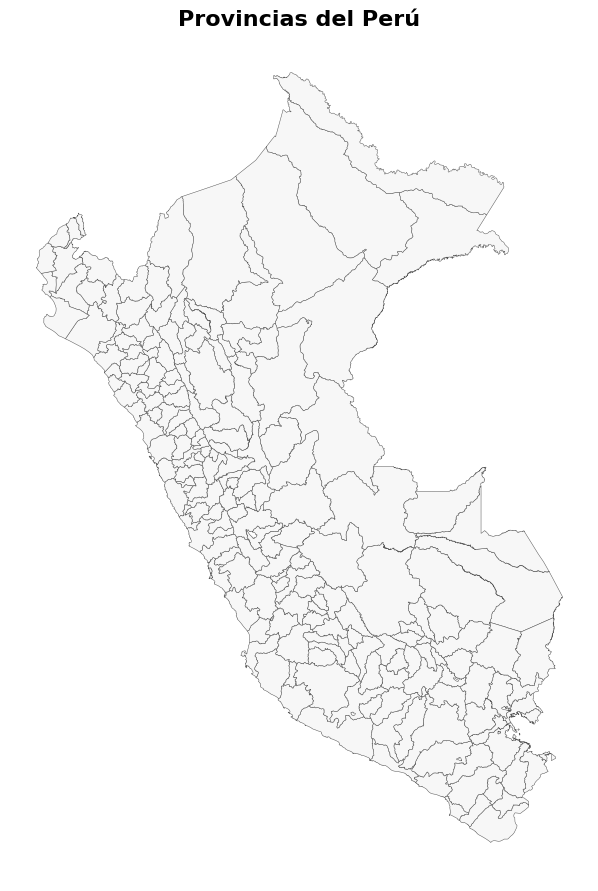

In [128]:
# Graficamos el mapa provincial

fig, ax = plt.subplots(figsize=(11, 11))

mapa.plot(
    ax=ax,
    facecolor="#F7F7F7",
    edgecolor="#555555",
    linewidth=0.35
)

ax.set_axis_off()

# Dejar espacio a la derecha para la leyenda
plt.subplots_adjust(right=0.72)

plt.title(
    "Provincias del Perú",
    fontsize=16,
    fontweight="bold"
)

plt.show()

In [129]:
# Normalizamos los nombres para unir la base electoral con el mapa

import unicodedata

def normalizar_nombre(texto):
    texto = str(texto).upper().strip()
    texto = unicodedata.normalize("NFD", texto)
    texto = "".join(
        c for c in texto
        if unicodedata.category(c) != "Mn"
    )
    return texto

# Base electoral
df["provincia_key"] = df["Provincia"].apply(normalizar_nombre)
df["departamento_key"] = df["Departamento"].apply(normalizar_nombre)

# Mapa
mapa["provincia_key"] = mapa["nombre"].apply(normalizar_nombre)
mapa["departamento_key"] = mapa["nombre_departamento"].apply(normalizar_nombre)

In [130]:
# Unimos la base electoral con el mapa y verificamos

mapa_final = mapa.merge(
    df,
    on=["departamento_key", "provincia_key"],
    how="left"
)

print("Provincias:", len(mapa_final))
print("Provincias con datos:", mapa_final["cambio_KF"].notna().sum())

Provincias: 196
Provincias con datos: 195


In [131]:
# Identificamos que provincias del Excel no encontraron equivalente en el mapa
keys_mapa = set(
    zip(mapa["departamento_key"], mapa["provincia_key"])
)

df_sin_match = df[
    ~df.apply(
        lambda x: (x["departamento_key"], x["provincia_key"]) in keys_mapa,
        axis=1
    )
]

df_sin_match[
    ["Departamento", "Provincia", "departamento_key", "provincia_key"]
]

,Departamento,Provincia,departamento_key,provincia_key
8,ANCASH,ANTONIO RAIMONDI,ANCASH,ANTONIO RAIMONDI


In [132]:
# Homologamos el nombre provincial que difiere

df.loc[
    (df["departamento_key"] == "ANCASH") &
    (df["provincia_key"] == "ANTONIO RAIMONDI"),
    "provincia_key"
] = "ANTONIO RAYMONDI"

In [133]:
# Realizamos el dataframe del mapa final

mapa_final = mapa.merge(
    df,
    on=["departamento_key", "provincia_key"],
    how="left"
)

print("Provincias en el mapa:", len(mapa_final))
print("Provincias con datos electorales:", mapa_final["cambio_KF"].notna().sum())
print("Provincias SIN datos electorales:", mapa_final["cambio_KF"].isna().sum())

Provincias en el mapa: 196
Provincias con datos electorales: 196
Provincias SIN datos electorales: 0


In [134]:
# Creamos un punto interno de referencia para cada provincia

mapa_final["punto"] = mapa_final.geometry.representative_point()

mapa_final["x"] = mapa_final["punto"].x
mapa_final["y"] = mapa_final["punto"].y

# Comprobación de los puntos

print("Número de puntos:", len(mapa_final))
mapa_final[["Departamento", "Provincia", "cambio_KF", "x", "y"]].head()

Número de puntos: 196


,Departamento,Provincia,cambio_KF,x,y
0,AMAZONAS,CHACHAPOYAS,5.842,-77.798379,-6.466226
1,AMAZONAS,BAGUA,2.262,-78.428509,-5.117608
2,AMAZONAS,BONGARA,5.859,-77.886106,-5.632026
3,AMAZONAS,CONDORCANQUI,0.233,-78.077604,-4.199996
4,AMAZONAS,LUYA,5.424,-78.132913,-6.323710


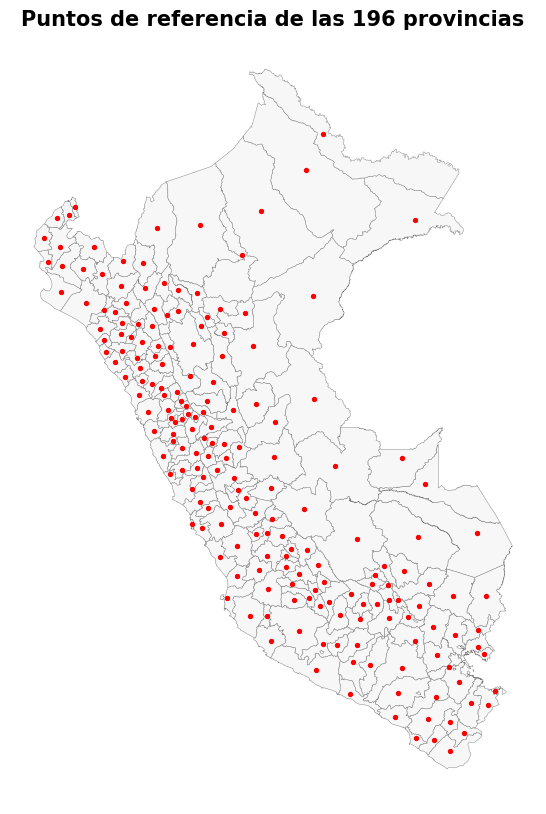

In [135]:
# Verificamos la ubicación de los puntos de referencia de cada provincia

fig, ax = plt.subplots(figsize=(8, 10))

# Graficamos las provincias

mapa_final.plot(
    ax=ax,
    facecolor="#F7F7F7",
    edgecolor="#777777",
    linewidth=0.3
)

# Mostramos los puntos de referencia

ax.scatter(
    mapa_final["x"],
    mapa_final["y"],
    s=8,
    color="red",
    zorder=3
)

ax.set_axis_off()
plt.title(
    "Puntos de referencia de las 196 provincias",
    fontsize=15,
    fontweight="bold"
)

plt.show()

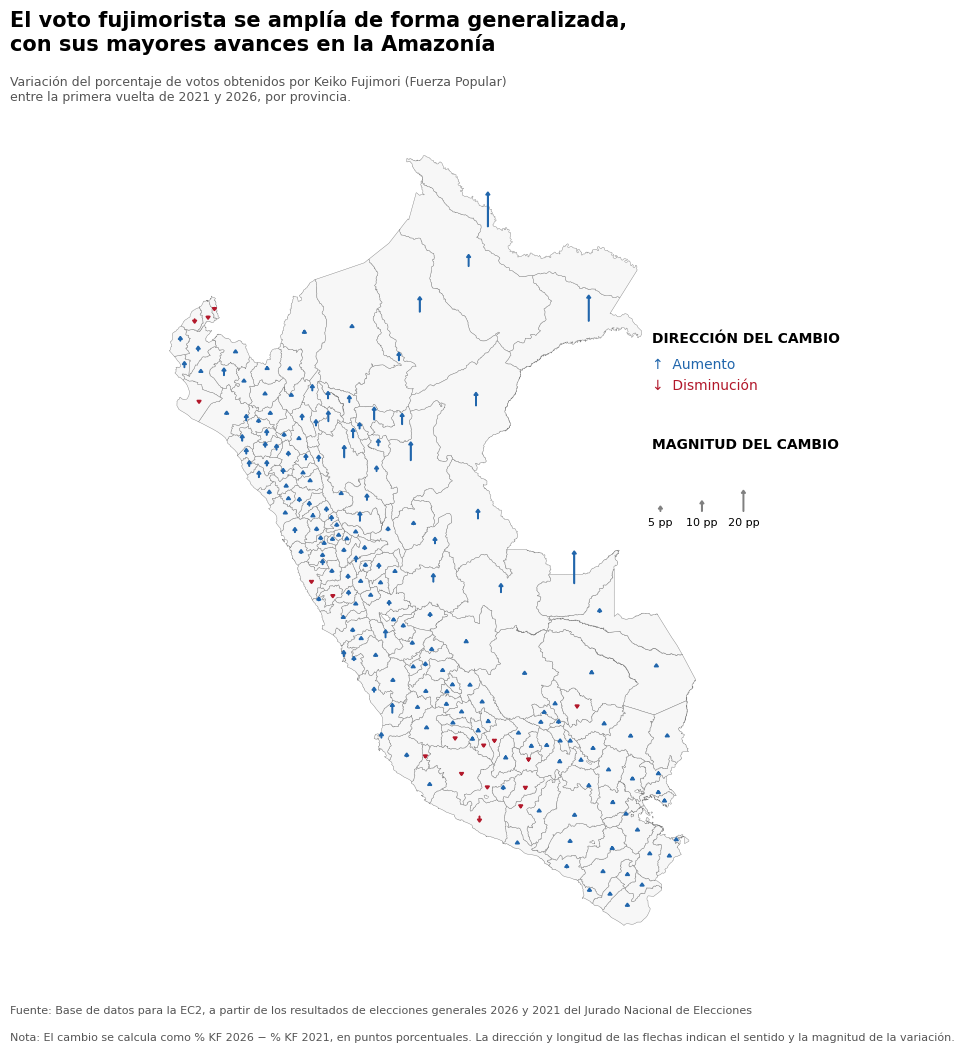

In [138]:
# Elaboramos el mapa final con la dirección y magnitud del cambio en el voto

escala = 0.025

# Creamos la figura
fig, ax = plt.subplots(figsize=(10, 11))

# Graficamos el mapa de provincias
mapa_final.plot(
    ax=ax,
    color="#F7F7F7",
    edgecolor="gray",
    linewidth=0.3
)

# Elaboramos las flechas según la dirección y magnitud del cambio
for _, fila in mapa_final.iterrows():

    cambio = fila["cambio_KF"]
    longitud = abs(cambio) * escala

    # Diferenciamos los aumentos y disminuciones
    if cambio >= 0:
        dy = longitud
        color = "#2166AC"
    else:
        dy = -longitud
        color = "#B2182B"

    # Dibujamos cada flecha desde el punto de referencia de la provincia
    ax.arrow(
        fila["x"],
        fila["y"],
        0,
        dy,
        width=0.014,
        head_width=0.10,
        head_length=0.07,
        color=color,
        length_includes_head=True
    )

# Ocultamos los ejes
ax.axis("off")

# Dejamos espacio a la derecha para la leyenda
ax.set_xlim(-82.5, -67)

# Agregamos la leyenda de dirección del cambio
ax.text(
    -69.7, -4.5,
    "DIRECCIÓN DEL CAMBIO",
    fontsize=10,
    fontweight="bold"
)

ax.text(
    -69.7, -5.1,
    "↑  Aumento",
    fontsize=10,
    color="#2166AC"
)

ax.text(
    -69.7, -5.6,
    "↓  Disminución",
    fontsize=10,
    color="#B2182B"
)

# Agregamos la leyenda de magnitud del cambio
ax.text(
    -69.7, -7.0,
    "MAGNITUD DEL CAMBIO",
    fontsize=10,
    fontweight="bold"
)

# Creamos flechas de referencia para 5, 10 y 20 puntos porcentuales
ax.arrow(
    -69.5, -8.5, 0, 5 * escala,
    width=0.014,
    head_width=0.10,
    head_length=0.07,
    color="gray",
    length_includes_head=True
)

ax.arrow(
    -68.5, -8.5, 0, 10 * escala,
    width=0.014,
    head_width=0.10,
    head_length=0.07,
    color="gray",
    length_includes_head=True
)

ax.arrow(
    -67.5, -8.5, 0, 20 * escala,
    width=0.014,
    head_width=0.10,
    head_length=0.07,
    color="gray",
    length_includes_head=True
)

# Agregamos las etiquetas de magnitud
ax.text(-69.5, -8.85, "5 pp", fontsize=8, ha="center")
ax.text(-68.5, -8.85, "10 pp", fontsize=8, ha="center")
ax.text(-67.5, -8.85, "20 pp", fontsize=8, ha="center")

# Agregamos el título
fig.text(
    0.08, 0.94,
    "El voto fujimorista se amplía de forma generalizada,\ncon sus mayores avances en la Amazonía",
    fontsize=15,
    fontweight="bold"
)

# Agregamos el subtítulo
fig.text(
    0.08, 0.895,
    "Variación del porcentaje de votos obtenidos por Keiko Fujimori (Fuerza Popular)\n"
    "entre la primera vuelta de 2021 y 2026, por provincia.",
    fontsize=9,
    color="#555555"
)

# Agregamos la fuente
fig.text(
    0.08, 0.065,
    "Fuente: Base de datos para la EC2, a partir de los resultados de elecciones generales 2026 y 2021 del Jurado Nacional de Elecciones",
    fontsize=8,
    color="#555555"
)

# Agregamos la nota metodológica
fig.text(
    0.08, 0.04,
    "Nota: El cambio se calcula como % KF 2026 − % KF 2021, en puntos porcentuales. La dirección y longitud de las flechas indican el sentido y la magnitud de la variación.",
    fontsize=8,
    color="#555555"
)

plt.show()

In [137]:
# Códigos para identificar datos para el storytelling/hallazgos

print("Promedio:", df["cambio_KF"].mean())
print("Mediana:", df["cambio_KF"].median())

print("\nMayores aumentos:")
display(
    df.nlargest(10, "cambio_KF")[
        ["Departamento", "Provincia", "cambio_KF"]
    ]
)

print("\nMayores caídas:")
display(
    df.nsmallest(10, "cambio_KF")[
        ["Departamento", "Provincia", "cambio_KF"]
    ]
)

print("Provincias donde aumentó:", (df["cambio_KF"] > 0).sum())
print("Provincias donde disminuyó:", (df["cambio_KF"] < 0).sum())

Promedio: 3.365336734693877
Mediana: 2.5325000000000015

Mayores aumentos:


,Departamento,Provincia,cambio_KF
142,LORETO,PUTUMAYO,32.997
195,UCAYALI,PURUS,30.967
140,LORETO,MARISCAL RAMON CASTILLA,24.760
144,LORETO,UCAYALI,17.656
139,LORETO,LORETO,14.626
143,LORETO,REQUENA,12.751
178,SAN MARTIN,LAMAS,12.092
179,SAN MARTIN,MARISCAL CACERES,11.574
141,LORETO,MAYNAS,11.344
183,SAN MARTIN,SAN MARTIN,10.481



Mayores caídas:


,Departamento,Provincia,cambio_KF
36,AREQUIPA,CARAVELI,-5.638
189,TUMBES,CONTRALMIRANTE VILLAR,-4.025
190,TUMBES,TUMBES,-2.952
191,TUMBES,ZARUMILLA,-2.935
159,PIURA,SECHURA,-2.840
17,ANCASH,HUARMEY,-2.601
48,AYACUCHO,PARINACOCHAS,-1.457
20,ANCASH,OCROS,-1.405
47,AYACUCHO,LUCANAS,-1.347
50,AYACUCHO,SUCRE,-0.732


Provincias donde aumentó: 179
Provincias donde disminuyó: 17
